# Module A -- Segmentation

Runs 7 classical segmentation methods (active contours, watershed, Felzenszwalb graph-based, mean shift, standalone region splitting, standalone region merging, Normalized Cut) on 5 frames from `data/line_video.mp4` plus a dedicated touching-objects stress frame, and compares them side by side.

In [ ]:
import sys, os
sys.path.insert(0, os.path.join(os.getcwd(), '..'))
from module_a_segmentation.run_comparison import main
main()


[precomputed -- see outputs/module_a_comparison_grid.png]


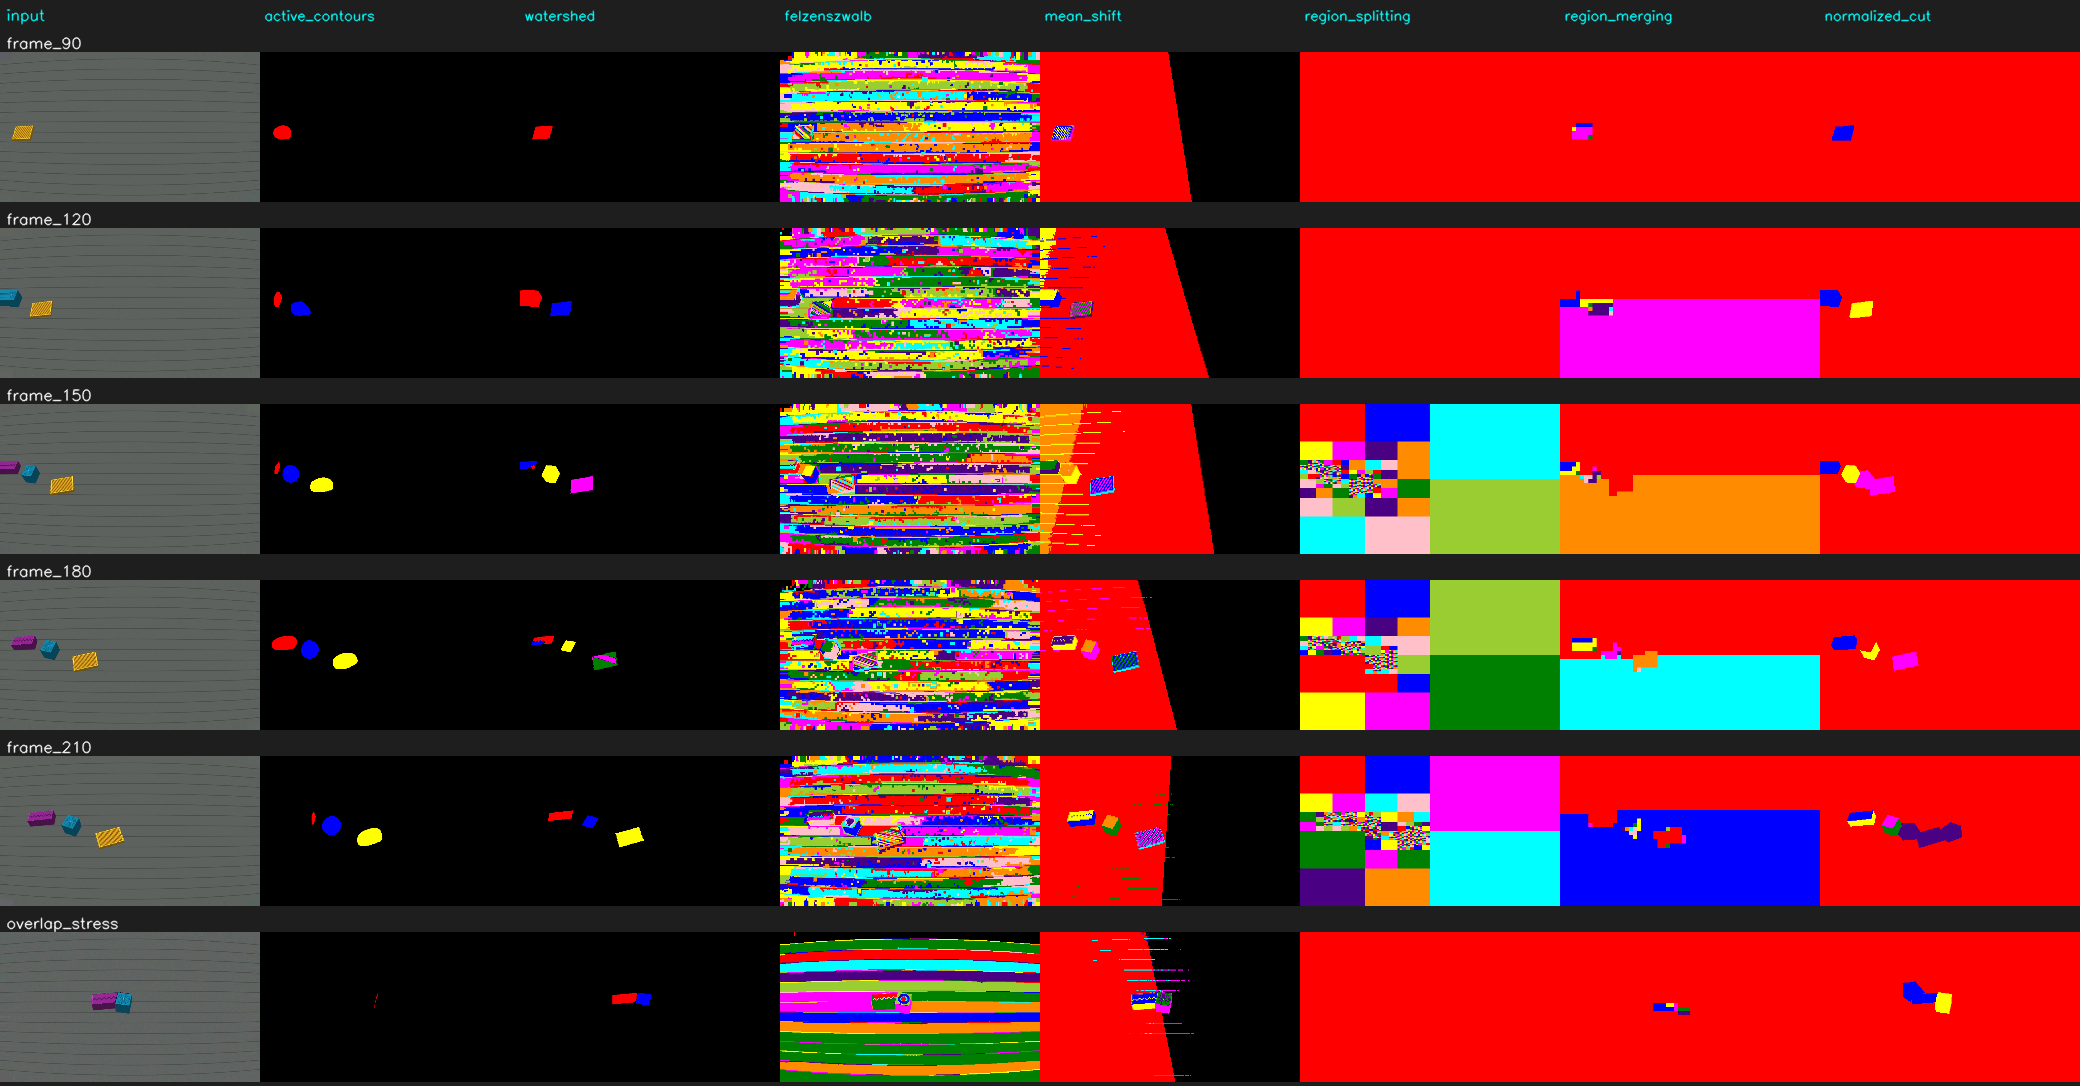

In [ ]:
from IPython.display import Image
Image('../outputs/module_a_comparison_grid.png')

Discussion: watershed handles the overlap_stress frame best -- seeding its
markers from LOCAL MAXIMA of the distance transform (one peak per object's
own "core"), rather than a single global threshold, lets it place two
separate markers inside the touching long_box/cube_carton pair and flood
each out to their true shared boundary. Active contours instead grows one
snake per *detected blob*; two touching parcels already form one connected
blob before the snake starts, so a single snake converges around both and
cannot split them -- on this frame it collapses to a near-empty contour.
Honest caveat: the same local-maxima seeding can over-segment a single
elongated parcel (long_box, 34x13cm) into two pieces even when it is alone,
since its distance transform has two broad peaks along its length -- a
known watershed failure mode, not hidden here. Region splitting and
Felzenszwalb both fragment printed textures into several small regions,
which is noisy but harmless; Normalized Cut on downsampled SLIC superpixels
is coarser still and can lump a parcel in with a strip of belt background.
